# Environmental Sound Classification using CNN
Pipeline: **ESC-50 audio clip → log-mel spectrogram (128 × 216) → CNN → one of 50 sound classes.**
Training is done by `train.py` (folds 1–3 train, fold 4 validation); this notebook explores the data and
analyses the trained model on the untouched **test fold 5**.

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import librosa, librosa.display, keras
from esc_cnn import config as C
from esc_cnn.features import load_audio, log_mel
from esc_cnn.data import load_features, split

meta = pd.read_csv(C.META_CSV)
print("clips:", len(meta), "| classes:", meta.target.nunique(), "| folds:", sorted(meta.fold.unique().tolist()))
print("clips per class:", meta.category.value_counts().unique(), "| ESC-10 subset clips:", meta.esc10.sum())
meta.head()

clips: 2000 | classes: 50 | folds: [1, 2, 3, 4, 5]
clips per class: [40] | ESC-10 subset clips: 400


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


### 1. What the sounds look like
Waveform (top) and log-mel spectrogram (bottom) for one clip of four very different classes.

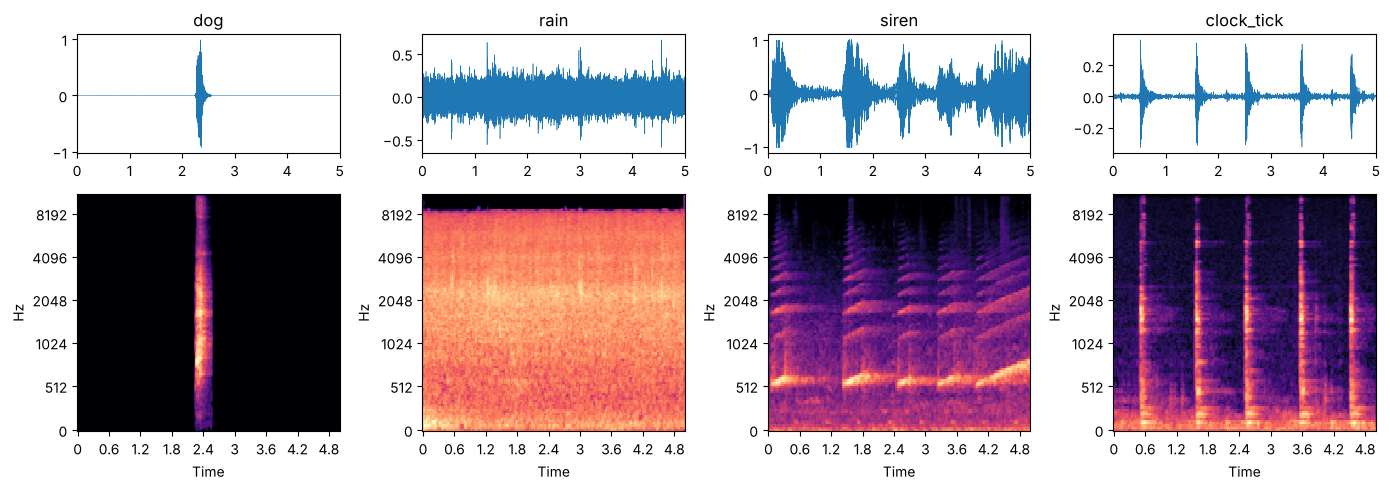

In [2]:
picks = ["dog", "rain", "siren", "clock_tick"]
fig, ax = plt.subplots(2, 4, figsize=(14, 5), gridspec_kw={"height_ratios": [1, 2]})
for j, name in enumerate(picks):
    f = meta[(meta.category == name) & (meta.fold == 1)].iloc[0].filename
    y = load_audio(C.AUDIO_DIR / f)
    ax[0, j].plot(np.arange(len(y)) / C.SR, y, lw=0.4); ax[0, j].set_title(name); ax[0, j].set_xlim(0, 5)
    librosa.display.specshow(log_mel(y), sr=C.SR, hop_length=C.HOP, x_axis="time", y_axis="mel", ax=ax[1, j], cmap="magma")
plt.tight_layout(); plt.show()

### 2. Cached features and the fold split

In [3]:
data = load_features()
for name, folds in [("train", [1, 2, 3]), ("validation", [4]), ("test", [5])]:
    X, y = split(data, folds)
    print(f"{name:<10} folds {folds}: X {X.shape}, {len(np.unique(y))} classes, {len(y)//len(np.unique(y))} clips per class")
print("value range after normalisation:", data["X"].min().round(2), "to", data["X"].max().round(2))

train      folds [1, 2, 3]: X (1200, 128, 216, 1), 50 classes, 24 clips per class
validation folds [4]: X (400, 128, 216, 1), 50 classes, 8 clips per class
test       folds [5]: X (400, 128, 216, 1), 50 classes, 8 clips per class
value range after normalisation: -1.0 to 1.0


### 3. Trained model

In [4]:
model = keras.models.load_model(C.RUNS_DIR / "esc50" / "best_model.keras")
model.summary(line_length=95)

Model: "ESC_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                            ┃ Output Shape                   ┃          Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ log_mel (InputLayer)                    │ (None, 128, 216, 1)            │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block1_conv (Conv2D)                    │ (None, 128, 216, 32)           │              288 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block1_bn (BatchNormalization)          │ (None, 128, 216, 32)           │              128 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block1_relu (ReLU)                      │ (None, 128, 216, 32)           │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block1_pool (MaxPooling2D)              │ (None, 64, 108, 32)            │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block2_conv (Conv2D)                    │ (None, 64, 108, 64)            │           18,432 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block2_bn (BatchNormalization)          │ (None, 64, 108, 64)            │              256 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block2_relu (ReLU)                      │ (None, 64, 108, 64)            │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block2_pool (MaxPooling2D)              │ (None, 32, 54, 64)             │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block3_conv (Conv2D)                    │ (None, 32, 54, 128)            │           73,728 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block3_bn (BatchNormalization)          │ (None, 32, 54, 128)            │              512 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block3_relu (ReLU)                      │ (None, 32, 54, 128)            │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block3_pool (MaxPooling2D)              │ (None, 16, 27, 128)            │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block4_conv (Conv2D)                    │ (None, 16, 27, 256)            │          294,912 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block4_bn (BatchNormalization)          │ (None, 16, 27, 256)            │            1,024 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block4_relu (ReLU)                      │ (None, 16, 27, 256)            │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block4_pool (MaxPooling2D)              │ (None, 8, 13, 256)             │                0 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block5_conv (Conv2D)                    │ (None, 8, 13, 256)             │          589,824 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block5_bn (BatchNormalization)          │ (None, 8, 13, 256)             │            1,024 │
├─────────────────────────────────────────┼────────────────────────────────┼──────────────────┤
│ block5_relu (ReLU)                      │ (None, 8, 13, 256)  

 Total params: 3,173,368 (12.11 MB)

 Trainable params: 1,057,298 (4.03 MB)

 Non-trainable params: 1,472 (5.75 KB)

 Optimizer params: 2,114,598 (8.07 MB)

### 4. Training history (from `runs/esc50/history.csv`)

epochs run: 91  | best epoch: 71  | training time: 53.8 min (CPU)


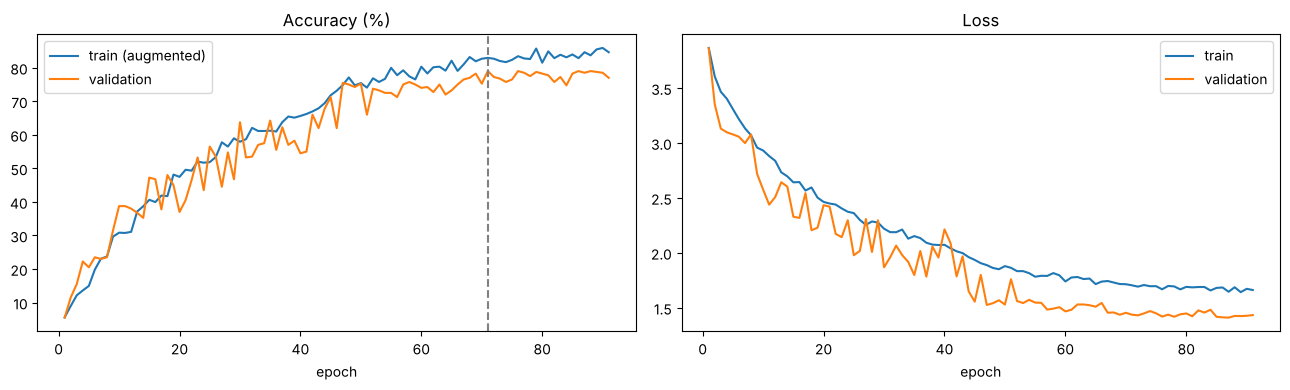

In [5]:
h = pd.read_csv(C.RUNS_DIR / "esc50" / "history.csv")
res = json.load(open(C.RUNS_DIR / "esc50" / "results.json"))
print(f"epochs run: {res['epochs_run']}  | best epoch: {res['best_epoch']}  | training time: {res['train_minutes']} min (CPU)")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h.epoch + 1, h.accuracy * 100, label="train (augmented)"); ax[0].plot(h.epoch + 1, h.val_accuracy * 100, label="validation")
ax[0].axvline(res["best_epoch"], ls="--", c="gray"); ax[0].set_title("Accuracy (%)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.epoch + 1, h.loss, label="train"); ax[1].plot(h.epoch + 1, h.val_loss, label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### 5. Evaluation on the unseen test fold (fold 5)

In [6]:
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix
Xte, yte = split(data, [5])
prob = model.predict(Xte, verbose=0); pred = prob.argmax(1)
names = data["class_names"]
print(f"Test accuracy : {accuracy_score(yte, pred):.2%}")
print(f"Top-3 accuracy: {top_k_accuracy_score(yte, prob, k=3):.2%}")
print(f"Macro F1      : {f1_score(yte, pred, average='macro'):.3f}")
cm = confusion_matrix(yte, pred)
per = pd.Series(cm.diagonal() / cm.sum(1), index=names).sort_values()
print("\nLowest per-class accuracy :", ", ".join(f"{k} {v:.0%}" for k, v in per.head(5).items()))
print("Highest per-class accuracy:", ", ".join(f"{k} {v:.0%}" for k, v in per.tail(5)[::-1].items()))

Test accuracy : 67.00%
Top-3 accuracy: 85.00%
Macro F1      : 0.646

Lowest per-class accuracy : helicopter 0%, airplane 0%, hen 12%, water_drops 12%, clapping 12%
Highest per-class accuracy: hand_saw 100%, clock_alarm 100%, glass_breaking 100%, rain 100%, cow 100%


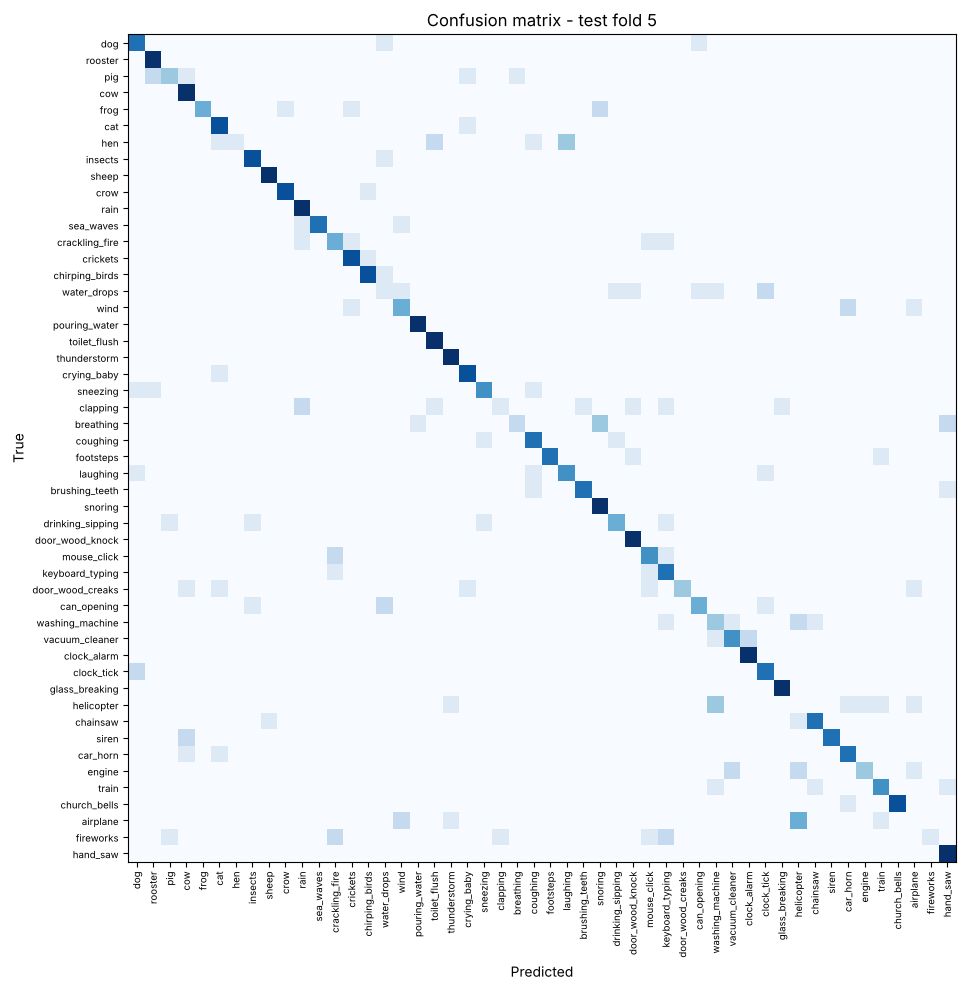

In [7]:
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(50), names, rotation=90, fontsize=7); ax.set_yticks(range(50), names, fontsize=7)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix - test fold 5")
plt.tight_layout(); plt.show()

### 6. Predictions on individual unseen clips

In [8]:
rng = np.random.RandomState(3)
idx = rng.choice(len(yte), 10, replace=False)
fn = data["filename"][np.isin(data["fold"], [5])]
rows = []
for i in idx:
    top = np.argsort(prob[i])[::-1][:3]
    rows.append({"file": fn[i], "true class": names[yte[i]], "predicted": names[top[0]],
                 "confidence": round(float(prob[i][top[0]]), 3),
                 "2nd / 3rd guess": f"{names[top[1]]} / {names[top[2]]}", "correct": names[top[0]] == names[yte[i]]})
pd.DataFrame(rows)

,file,true class,predicted,confidence,2nd / 3rd guess,correct
0,5-259640-A-29.wav,drinking_sipping,sneezing,0.558,drinking_sipping / dog,False
1,5-150409-A-42.wav,siren,siren,0.290,church_bells / car_horn,True
2,5-254160-A-22.wav,clapping,toilet_flush,0.135,brushing_teeth / clapping,False
3,5-185908-A-18.wav,toilet_flush,toilet_flush,0.896,sea_waves / vacuum_cleaner,True
4,5-194899-B-3.wav,cow,cow,0.975,sheep / chainsaw,True
5,5-215172-A-13.wav,crickets,crickets,0.993,wind / chirping_birds,True
6,5-263902-A-36.wav,vacuum_cleaner,vacuum_cleaner,0.969,clock_alarm / washing_machine,True
7,5-177957-E-40.wav,helicopter,washing_machine,0.310,airplane / helicopter,False
8,5-220027-A-21.wav,sneezing,sneezing,0.514,dog / coughing,True
9,5-161270-B-33.wav,door_wood_creaks,airplane,0.221,washing_machine / engine,False


### 7. Summary of both experiments

In [9]:
summ = []
for sub in ["esc50", "esc10"]:
    p = C.RUNS_DIR / sub / "results.json"
    if p.exists():
        r = json.load(open(p)); e = json.load(open(C.RUNS_DIR / sub / "eval" / "metrics.json"))
        summ.append({"dataset": sub.upper(), "classes": r["classes"], "train/val/test clips": f"{r['train_clips']}/{r['val_clips']}/{r['test_clips']}",
                     "best epoch": r["best_epoch"], "val acc": f"{r['val_accuracy']:.1%}", "test acc": f"{e['accuracy']:.1%}",
                     "top-3": f"{e['top3_accuracy']:.1%}", "macro F1": e["macro_f1"]})
pd.DataFrame(summ)

,dataset,classes,train/val/test clips,best epoch,val acc,test acc,top-3,macro F1
0,ESC50,50,1200/400/400,71,79.0%,67.0%,85.0%,0.6456
1,ESC10,10,240/80/80,66,95.0%,90.0%,97.5%,0.8981
